# 05 - Clasificación de Marcha Sagital: Niños Control vs. Parálisis Cerebral

Implementa la clasificación binaria entre **marcha típica (control)** y **marcha con parálisis cerebral / diplejía (case)** a partir de los ciclos de marcha cinemáticos sagitales normalizados (`gait_cycles_normalized_sagittal.parquet`) en la carpeta `derivatives/`.

### Características del Pipeline:
1. **Dato de entrada:** Ciclos cinemáticos normalizados a 101 puntos temporales ($0\%$ a $100\%$ del ciclo de paso) de Cadera, Rodilla y Tobillo en el plano sagital para ambos miembros inferiores (6 señales continuas bilaterales).
2. **Particionamiento Patient-Wise (Train / Val / Test):** División estricta a nivel de sujeto ($70\%$ train, $15\%$ validación, $15\%$ prueba) estratificada por clase para asegurar cero fuga de información (*zero data leakage*) entre trials y pasos del mismo niño.
3. **Modelado Dual:**
   - **Modelo A (Baseline Clínico Interpretable):** Random Forest sobre biomarcadores biomecánicos (ROM - Range of Motion, medias, desviaciones típicas, valores pico y asimetría inter-extremidades).
   - **Modelo B (Deep Learning 1D):** Red Convolucional Temporal (`GaitCNN1D`) que procesa directamente las curvas temporales completas ($6 \times 101$).
4. **Métricas a Doble Nivel (Ciclo y Paciente):**
   - **Nivel Ciclo / Trial:** Accuracy, Balanced Accuracy, Sensibilidad, Especificidad, F1-Score, ROC-AUC.
   - **Nivel Paciente / Sujeto:** Agregación clínica por votación mayoritaria y probabilidad promedio de los ciclos de cada niño.

In [ ]:
import sys, os
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, f1_score
)

from src.sagittal import (
    load_sagittal_dataset,
    patient_wise_stratified_split,
    GaitCNN1D,
    evaluate_patient_level_binary,
    SIGNALS,
    SIGNAL_NAMES
)

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo de computo disponible: {device}')

Dispositivo de computo disponible: cpu


## 1. Carga del Dataset e Inventario de Sujetos y Ciclos

Cargamos todos los archivos `gait_cycles_normalized_sagittal.parquet` de la carpeta `derivatives/`, vinculando cada sujeto con su grupo clínico (`case` = parálisis cerebral vs `control` = marcha típica) a través del archivo de metadatos.

In [ ]:
DERIVATIVES_DIR = '../derivatives'
SPLIT_CSV = '../derivatives/time_series_prediction/subject_split.csv'

df_cycles, X_curves, X_tabular, y, subjects, feature_names = load_sagittal_dataset(
    derivatives_dir=DERIVATIVES_DIR,
    split_csv_path=SPLIT_CSV
)

print('=== RESUMEN DEL DATASET CARGADO ===')
print(f'Total ciclos bilaterales completos: {len(df_cycles)}')
print(f'Forma tensor de curvas continuas (N, canales, puntos): {X_curves.shape}')
print(f'Forma matriz de caracteristicas tabulares (N, features): {X_tabular.shape}')
print(f'Numero total de sujetos unicos: {df_cycles["subject_id"].nunique()}')
print(f'Numero total de trials: {df_cycles.groupby(["subject_id", "trial_label"]).ngroups}')

print('\nDistribucion por Grupo Clinico:')
for grp, count in df_cycles.groupby('group')['subject_id'].nunique().items():
    n_c = (df_cycles['group'] == grp).sum()
    n_t = df_cycles[df_cycles['group'] == grp].groupby(['subject_id', 'trial_label']).ngroups
    print(f'  - Grupo {grp.upper():<7}: {count:>2} sujetos | {n_t:>2} trials | {n_c:>3} ciclos ({n_c/len(df_cycles)*100:.1f}%)')

df_cycles.head(6)

=== RESUMEN DEL DATASET CARGADO ===
Total ciclos bilaterales completos: 212
Forma tensor de curvas continuas (N, canales, puntos): (212, 6, 101)
Forma matriz de caracteristicas tabulares (N, features): (212, 36)
Numero total de sujetos unicos: 56
Numero total de trials: 57

Distribucion por Grupo Clinico:
  - Grupo CASE   : 17 sujetos | 17 trials |  52 ciclos (24.5%)
  - Grupo CONTROL: 39 sujetos | 40 trials | 160 ciclos (75.5%)


,subject_id,trial_label,cycle_id,group,label,is_best,source_file
0,subject_0001,trial_01,0,case,1,True,../derivatives/subject_0001/session_01/pose/tr...
1,subject_0001,trial_01,1,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
2,subject_0001,trial_01,2,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
3,subject_0001,trial_01,3,case,1,False,../derivatives/subject_0001/session_01/pose/tr...
4,subject_0010,trial_01,0,case,1,True,../derivatives/subject_0010/session_01/pose/tr...
5,subject_0010,trial_01,1,case,1,False,../derivatives/subject_0010/session_01/pose/tr...


## 2. Análisis Exploratorio: Curvas Cinemáticas Sagitales Promedio

En el análisis clínico de marcha, el estándar de oro es representar el ciclo de marcha normalizado del $0\%$ (contacto inicial de talón) al $100\%$ (siguiente contacto del mismo pie).
A continuación, comparamos las curvas promedio (con banda de $\pm 1$ desviación estándar) entre niños **Control** y niños con **Parálisis Cerebral** para Cadera, Rodilla y Tobillo.

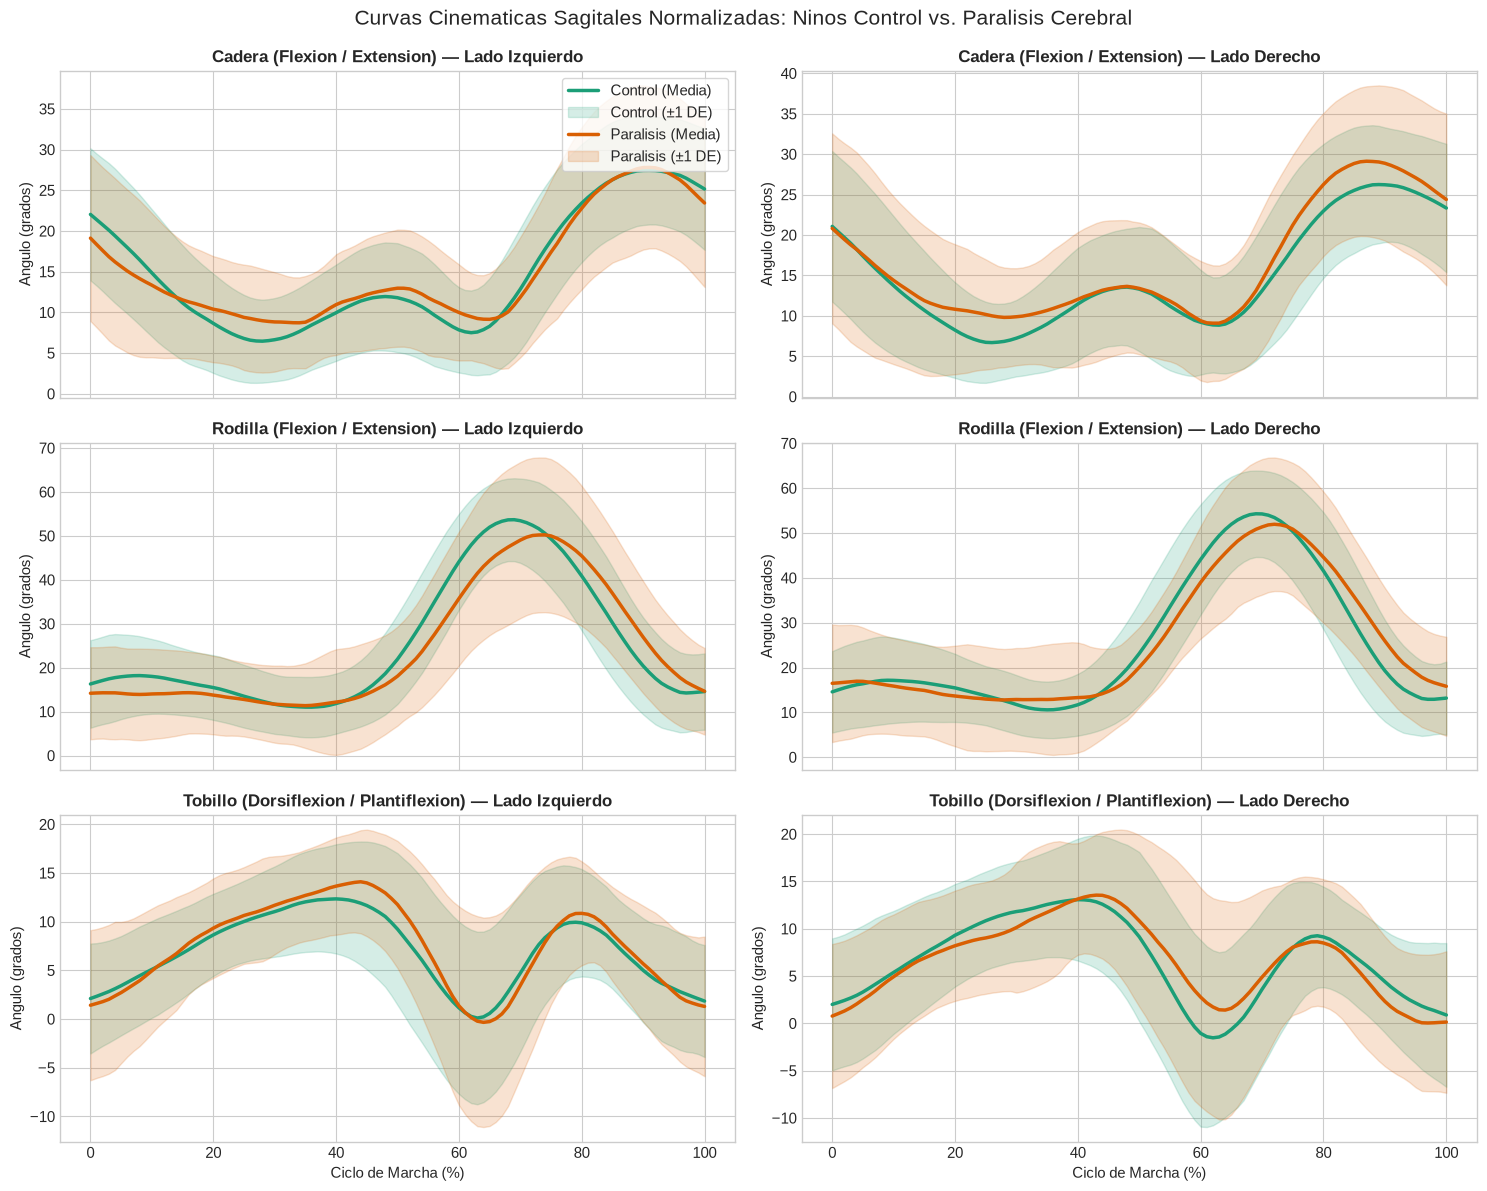

In [3]:
pct = np.linspace(0, 100, 101)

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)

joints = [('hip', 'Cadera (Flexion / Extension)'), 
          ('knee', 'Rodilla (Flexion / Extension)'), 
          ('ankle', 'Tobillo (Dorsiflexion / Plantiflexion)')]

sides = [('left', 'Lado Izquierdo'), ('right', 'Lado Derecho')]

ctrl_mask = (y == 0)
case_mask = (y == 1)

for r, (joint, joint_title) in enumerate(joints):
    for c, (side, side_title) in enumerate(sides):
        ax = axes[r, c]
        # Encontrar indice del canal
        sig_idx = SIGNALS.index((side, joint))
        
        # Curvas control
        ctrl_vals = X_curves[ctrl_mask, sig_idx, :]
        ctrl_mean = np.mean(ctrl_vals, axis=0)
        ctrl_std  = np.std(ctrl_vals, axis=0)
        
        # Curvas parálisis (case)
        case_vals = X_curves[case_mask, sig_idx, :]
        case_mean = np.mean(case_vals, axis=0)
        case_std  = np.std(case_vals, axis=0)
        
        # Plot
        ax.plot(pct, ctrl_mean, color='#1b9e77', lw=2.5, label='Control (Media)')
        ax.fill_between(pct, ctrl_mean - ctrl_std, ctrl_mean + ctrl_std, color='#1b9e77', alpha=0.18, label='Control (±1 DE)')
        
        ax.plot(pct, case_mean, color='#d95f02', lw=2.5, label='Paralisis (Media)')
        ax.fill_between(pct, case_mean - case_std, case_mean + case_std, color='#d95f02', alpha=0.18, label='Paralisis (±1 DE)')
        
        ax.set_title(f'{joint_title} — {side_title}', fontweight='bold')
        ax.set_ylabel('Angulo (grados)')
        if r == 2:
            ax.set_xlabel('Ciclo de Marcha (%)')
        if r == 0 and c == 0:
            ax.legend(loc='upper right', frameon=True)
            
plt.suptitle('Curvas Cinematicas Sagitales Normalizadas: Ninos Control vs. Paralisis Cerebral', fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

### Observaciones Clínicas Clave:
1. **Tobillo:** Se observa una marcada alteración en la dorsiflexión/plantiflexión en niños con parálisis, característica del patrón de **marcha en equino** (menor dorsiflexión en contacto inicial y fase de balanceo).
2. **Rodilla:** Los niños con parálisis presentan menor extensión terminal y un patrón alterado de flexión en fase de oscilación (marcha agazapada / *crouch gait* o *stiff knee*).
3. **Cadera:** Mayor variabilidad inter-sujeto y flexión sostenida aumentada durante la fase de apoyo.

## 3. Características Biomecánicas Clínicas y Asimetría

Extraemos descriptores clínicamente relevantes:
- **Range of Motion (ROM):** $\text{ROM} = \max(\theta) - \min(\theta)$ por articulación.
- **Asimetría Inter-extremidades:** Diferencia absoluta de ROM entre el lado izquierdo y derecho: $|\text{ROM}_{\text{izq}} - \text{ROM}_{\text{der}}|$.

/tmp/ipykernel_23518/3603657152.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='left_hip_rom', data=df_features, ax=axes[0], palette=['#1b9e77', '#d95f02'])
/tmp/ipykernel_23518/3603657152.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='left_knee_rom', data=df_features, ax=axes[1], palette=['#1b9e77', '#d95f02'])
/tmp/ipykernel_23518/3603657152.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='asymmetry_rom_knee', data=df_features, ax=axes[2], palette=['#1b9e77', '#d95f02'])


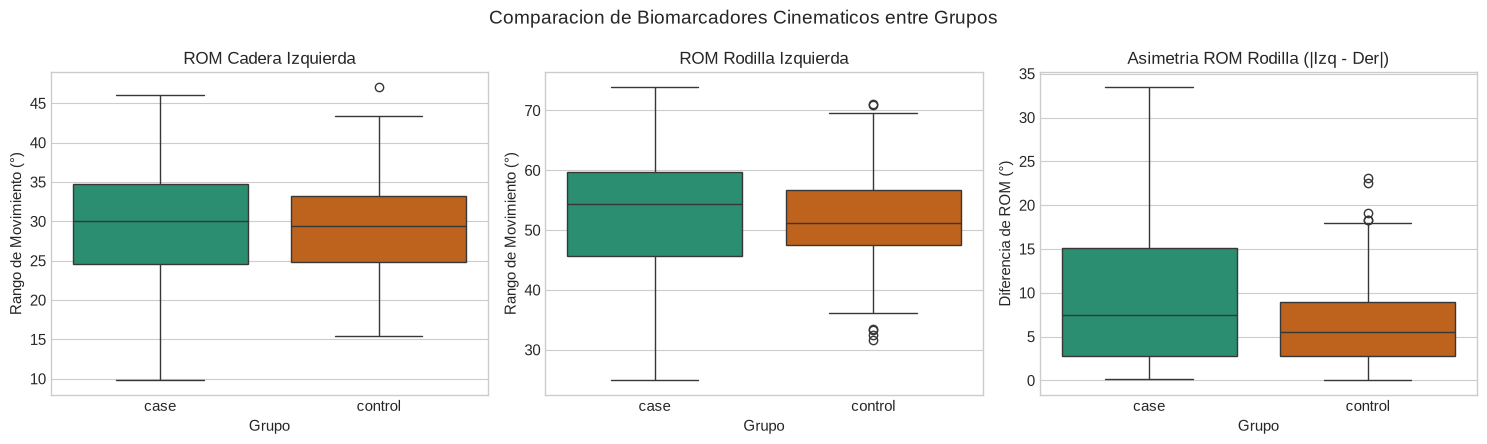

In [4]:
# Crear un DataFrame con las características biomecánicas para graficar
df_features = pd.DataFrame(X_tabular, columns=feature_names)
df_features['group'] = df_cycles['group'].values

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

box_props = dict(boxprops=dict(facecolor='none'), medianprops=dict(color='black', lw=2))

# 1. ROM Cadera
sns.boxplot(x='group', y='left_hip_rom', data=df_features, ax=axes[0], palette=['#1b9e77', '#d95f02'])
axes[0].set_title('ROM Cadera Izquierda')
axes[0].set_ylabel('Rango de Movimiento (°)')
axes[0].set_xlabel('Grupo')

# 2. ROM Rodilla
sns.boxplot(x='group', y='left_knee_rom', data=df_features, ax=axes[1], palette=['#1b9e77', '#d95f02'])
axes[1].set_title('ROM Rodilla Izquierda')
axes[1].set_ylabel('Rango de Movimiento (°)')
axes[1].set_xlabel('Grupo')

# 3. Asimetría de Rodilla
sns.boxplot(x='group', y='asymmetry_rom_knee', data=df_features, ax=axes[2], palette=['#1b9e77', '#d95f02'])
axes[2].set_title('Asimetria ROM Rodilla (|Izq - Der|)')
axes[2].set_ylabel('Diferencia de ROM (°)')
axes[2].set_xlabel('Grupo')

plt.suptitle('Comparacion de Biomarcadores Cinematicos entre Grupos', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Particionamiento Patient-Wise (Train / Validación / Prueba)

Para evitar la fuga de información (*data leakage*), la partición se realiza **a nivel paciente**. Todos los trials y ciclos pertenecientes al mismo niño se ubican estrictamente en un único conjunto:
- **Entrenamiento ($70\%$):** Para ajuste de pesos y parámetros.
- **Validación ($15\%$):** Para sintonización de hiperparámetros y selección del mejor checkpoint.
- **Prueba ($15\%$):** Para la evaluación final independiente no vista durante el entrenamiento.

In [5]:
train_idx, val_idx, test_idx, split_subjs = patient_wise_stratified_split(
    y, subjects, train_ratio=0.70, val_ratio=0.15, test_ratio=0.15, seed=42
)

# Validar ausencia de fuga de sujetos
s_train = set(split_subjs['train'])
s_val   = set(split_subjs['val'])
s_test  = set(split_subjs['test'])

assert len(s_train.intersection(s_val)) == 0, 'ERROR: Fuga de sujetos entre Train y Val'
assert len(s_train.intersection(s_test)) == 0, 'ERROR: Fuga de sujetos entre Train y Test'
assert len(s_val.intersection(s_test)) == 0, 'ERROR: Fuga de sujetos entre Val y Test'

print('=== PARTICION PATIENT-WISE VALIDADA (CERO FUGA) ===')
splits_info = [
    ('Train', train_idx, s_train),
    ('Validation', val_idx, s_val),
    ('Test', test_idx, s_test),
]

summary_rows = []
for name, idxs, s_set in splits_info:
    y_part = y[idxs]
    n_ctrl = np.sum(y_part == 0)
    n_case = np.sum(y_part == 1)
    n_subjs_ctrl = len([s for s in s_set if df_cycles[df_cycles['subject_id'] == s]['group'].iloc[0] == 'control'])
    n_subjs_case = len([s for s in s_set if df_cycles[df_cycles['subject_id'] == s]['group'].iloc[0] == 'case'])
    summary_rows.append({
        'Particion': name,
        'Sujetos Totales': len(s_set),
        'Sujetos Control': n_subjs_ctrl,
        'Sujetos Paralisis': n_subjs_case,
        'Ciclos Totales': len(idxs),
        'Ciclos Control': n_ctrl,
        'Ciclos Paralisis': n_case
    })

df_split_summary = pd.DataFrame(summary_rows)
df_split_summary

=== PARTICION PATIENT-WISE VALIDADA (CERO FUGA) ===


,Particion,Sujetos Totales,Sujetos Control,Sujetos Paralisis,Ciclos Totales,Ciclos Control,Ciclos Paralisis
0,Train,38,27,11,145,108,37
1,Validation,9,6,3,39,29,10
2,Test,9,6,3,28,23,5


## 5. Modelo A: Baseline Clínico Interpretable (Random Forest)

Entrenamos un clasificador **Random Forest** sobre las características tabulares biomecánicas (`X_tabular`), incorporando balanceo de clases mediante pesos de muestra inversos a la frecuencia.

=== RESULTADOS RANDOM FOREST (NIVEL CICLO) ===
Accuracy en Validacion:  69.23%
Accuracy en Test:        75.00%
Balanced Acc en Test:    53.48%
ROC-AUC en Test:         0.6957


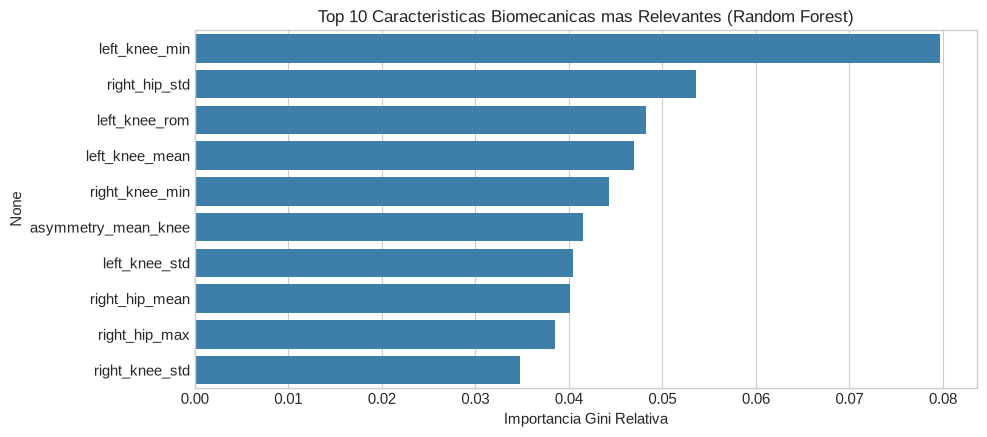

In [6]:
# Ajuste de Random Forest
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=6,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_tabular[train_idx], y[train_idx])

# Predicciones
rf_val_preds = rf.predict(X_tabular[val_idx])
rf_val_probs = rf.predict_proba(X_tabular[val_idx])[:, 1]

rf_test_preds = rf.predict(X_tabular[test_idx])
rf_test_probs = rf.predict_proba(X_tabular[test_idx])[:, 1]

# Métricas a nivel ciclo
rf_val_acc = accuracy_score(y[val_idx], rf_val_preds)
rf_test_acc = accuracy_score(y[test_idx], rf_test_preds)
rf_test_bal_acc = balanced_accuracy_score(y[test_idx], rf_test_preds)
rf_test_auc = roc_auc_score(y[test_idx], rf_test_probs)

print('=== RESULTADOS RANDOM FOREST (NIVEL CICLO) ===')
print(f'Accuracy en Validacion:  {rf_val_acc*100:.2f}%')
print(f'Accuracy en Test:        {rf_test_acc*100:.2f}%')
print(f'Balanced Acc en Test:    {rf_test_bal_acc*100:.2f}%')
print(f'ROC-AUC en Test:         {rf_test_auc:.4f}')

# Importancia de Características Top 10
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, color='#2b83ba')
plt.title('Top 10 Caracteristicas Biomecanicas mas Relevantes (Random Forest)')
plt.xlabel('Importancia Gini Relativa')
plt.tight_layout()
plt.show()

## 6. Modelo B: Red Convolucional 1D (`GaitCNN1D`) sobre Curvas Continuas

La red convolucional temporal extrae patrones dinámicos locales y globales a lo largo de los 101 puntos del ciclo para los 6 canales cinemáticos.

In [7]:
# Preparación de Tensores PyTorch
X_train_t = torch.tensor(X_curves[train_idx], dtype=torch.float32)
y_train_t = torch.tensor(y[train_idx], dtype=torch.long)

X_val_t   = torch.tensor(X_curves[val_idx], dtype=torch.float32)
y_val_t   = torch.tensor(y[val_idx], dtype=torch.long)

X_test_t  = torch.tensor(X_curves[test_idx], dtype=torch.float32)
y_test_t  = torch.tensor(y[test_idx], dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=16, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=16, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=16, shuffle=False)

# Pesos de clase para CrossEntropyLoss ponderada
n_ctrl_tr = np.sum(y[train_idx] == 0)
n_case_tr = np.sum(y[train_idx] == 1)
weights = torch.tensor([1.0, float(n_ctrl_tr) / float(n_case_tr)], dtype=torch.float32).to(device)

torch.manual_seed(42)
cnn_model = GaitCNN1D(in_channels=6, num_classes=2, dropout=0.3).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)

epochs = 40
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(1, epochs + 1):
    cnn_model.train()
    running_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        out = cnn_model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(by)
        preds = torch.argmax(out, dim=1)
        correct += (preds == by).sum().item()
        total += len(by)
        
    scheduler.step()
    tr_loss = running_loss / total
    tr_acc = correct / total
    
    # Evaluación en Validación
    cnn_model.eval()
    v_loss, v_corr, v_tot = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            out = cnn_model(bx)
            loss = criterion(out, by)
            v_loss += loss.item() * len(by)
            preds = torch.argmax(out, dim=1)
            v_corr += (preds == by).sum().item()
            v_tot += len(by)
            
    val_loss = v_loss / v_tot
    val_acc = v_corr / v_tot
    
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(val_acc)
    
    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoca {epoch:02d}/{epochs:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.1f}% | Val Loss: {val_loss:.4f} Acc: {val_acc*100:.1f}%')

Epoca 01/40 | Train Loss: 0.6733 Acc: 72.4% | Val Loss: 0.6815 Acc: 66.7%


Epoca 10/40 | Train Loss: 0.2689 Acc: 93.1% | Val Loss: 0.8804 Acc: 69.2%


Epoca 20/40 | Train Loss: 0.2855 Acc: 88.3% | Val Loss: 0.9199 Acc: 69.2%


Epoca 30/40 | Train Loss: 0.1061 Acc: 97.2% | Val Loss: 0.9754 Acc: 66.7%


Epoca 40/40 | Train Loss: 0.1174 Acc: 95.2% | Val Loss: 1.0421 Acc: 69.2%


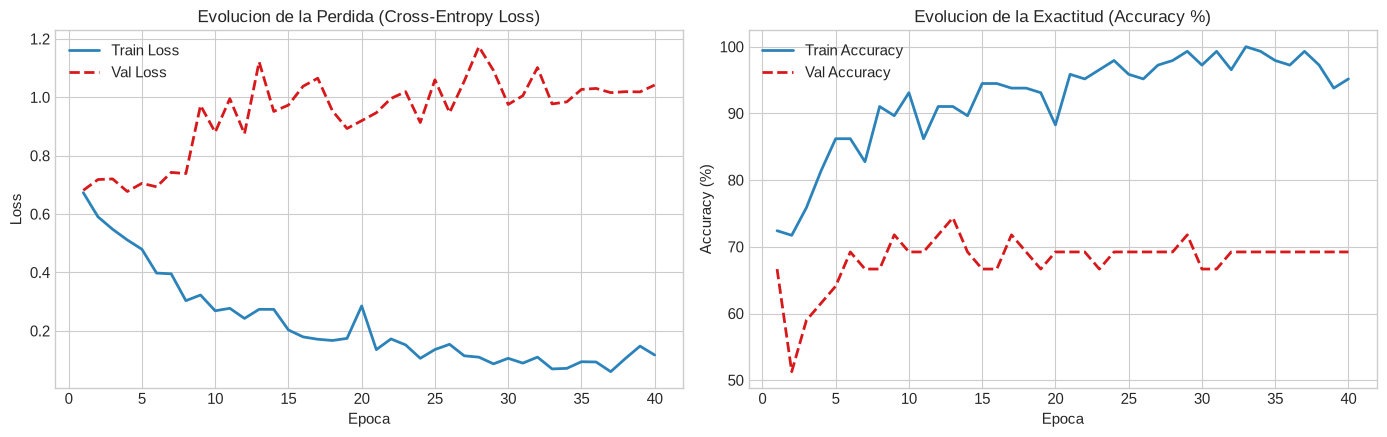

In [8]:
# Graficar curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(range(1, epochs + 1), history['train_loss'], label='Train Loss', color='#2b83ba', lw=2)
axes[0].plot(range(1, epochs + 1), history['val_loss'], label='Val Loss', color='#d7191c', lw=2, linestyle='--')
axes[0].set_title('Evolucion de la Perdida (Cross-Entropy Loss)')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(range(1, epochs + 1), [a*100 for a in history['train_acc']], label='Train Accuracy', color='#2b83ba', lw=2)
axes[1].plot(range(1, epochs + 1), [a*100 for a in history['val_acc']], label='Val Accuracy', color='#d7191c', lw=2, linestyle='--')
axes[1].set_title('Evolucion de la Exactitud (Accuracy %)')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# Inferencia en Test
cnn_model.eval()
all_probs, all_preds = [], []
with torch.no_grad():
    for bx, _ in test_loader:
        bx = bx.to(device)
        logits = cnn_model(bx)
        probs = torch.softmax(logits, dim=1)[:, 1]
        preds = torch.argmax(logits, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

cnn_test_preds = np.array(all_preds)
cnn_test_probs = np.array(all_probs)

cnn_test_acc = accuracy_score(y[test_idx], cnn_test_preds)
cnn_test_bal = balanced_accuracy_score(y[test_idx], cnn_test_preds)
cnn_test_auc = roc_auc_score(y[test_idx], cnn_test_probs)

print('=== RESULTADOS GAIT-CNN1D (NIVEL CICLO EN TEST) ===')
print(f'Test Accuracy:         {cnn_test_acc*100:.2f}%')
print(f'Test Balanced Acc:     {cnn_test_bal*100:.2f}%')
print(f'Test ROC-AUC:          {cnn_test_auc:.4f}')

=== RESULTADOS GAIT-CNN1D (NIVEL CICLO EN TEST) ===
Test Accuracy:         64.29%
Test Balanced Acc:     54.78%
Test ROC-AUC:          0.5478


## 7. Evaluación a Nivel Paciente y Comparativa Final

En el contexto médico real, el diagnóstico clínico se emite **por niño** (sujeto), no por ciclo aislado. 
Agregamos los ciclos de cada paciente en el conjunto de prueba independiente promediando las probabilidades predichas y aplicando votación de consenso.

In [10]:
# Evaluación a nivel paciente para Random Forest
rf_patient_metrics, df_rf_patients = evaluate_patient_level_binary(
    y_true=y[test_idx],
    y_pred=rf_test_preds,
    y_prob=rf_test_probs,
    subjects=subjects[test_idx]
)

# Evaluación a nivel paciente para GaitCNN1D
cnn_patient_metrics, df_cnn_patients = evaluate_patient_level_binary(
    y_true=y[test_idx],
    y_pred=cnn_test_preds,
    y_prob=cnn_test_probs,
    subjects=subjects[test_idx]
)

print('=== EVALUACION INDEPENDIENTE A NIVEL PACIENTE (TEST SET) ===')
metrics_comparison = pd.DataFrame([
    {
        'Modelo': 'Random Forest (Biomecanico)',
        'Acc Paciente': f"{rf_patient_metrics['accuracy']*100:.1f}%",
        'Balanced Acc': f"{rf_patient_metrics['balanced_accuracy']*100:.1f}%",
        'Sensibilidad (Recall)': f"{rf_patient_metrics['sensitivity']*100:.1f}%",
        'Especificidad': f"{rf_patient_metrics['specificity']*100:.1f}%",
        'F1-Score': f"{rf_patient_metrics['f1_score']:.3f}",
        'ROC-AUC': f"{rf_patient_metrics['roc_auc']:.3f}"
    },
    {
        'Modelo': 'GaitCNN1D (Series Continuas)',
        'Acc Paciente': f"{cnn_patient_metrics['accuracy']*100:.1f}%",
        'Balanced Acc': f"{cnn_patient_metrics['balanced_accuracy']*100:.1f}%",
        'Sensibilidad (Recall)': f"{cnn_patient_metrics['sensitivity']*100:.1f}%",
        'Especificidad': f"{cnn_patient_metrics['specificity']*100:.1f}%",
        'F1-Score': f"{cnn_patient_metrics['f1_score']:.3f}",
        'ROC-AUC': f"{cnn_patient_metrics['roc_auc']:.3f}"
    }
])
metrics_comparison

=== EVALUACION INDEPENDIENTE A NIVEL PACIENTE (TEST SET) ===


,Modelo,Acc Paciente,Balanced Acc,Sensibilidad (Recall),Especificidad,F1-Score,ROC-AUC
0,Random Forest (Biomecanico),66.7%,50.0%,0.0%,100.0%,0.000,0.667
1,GaitCNN1D (Series Continuas),66.7%,58.3%,33.3%,83.3%,0.400,0.500


In [11]:
print('Diagnostico Detallado por Paciente en Test (GaitCNN1D):')
df_cnn_patients_display = df_cnn_patients.copy()
df_cnn_patients_display['Diagnostico Real'] = df_cnn_patients_display['true_label'].map({0: 'Control', 1: 'Paralisis'})
df_cnn_patients_display['Diagnostico Predicho'] = df_cnn_patients_display['pred_label'].map({0: 'Control', 1: 'Paralisis'})
df_cnn_patients_display['Prob. Paralisis'] = df_cnn_patients_display['mean_prob'].map(lambda p: f'{p:.3f}')
df_cnn_patients_display[['subject', 'n_cycles', 'Diagnostico Real', 'Diagnostico Predicho', 'Prob. Paralisis']]

Diagnostico Detallado por Paciente en Test (GaitCNN1D):


,subject,n_cycles,Diagnostico Real,Diagnostico Predicho,Prob. Paralisis
0,subject_0015,2,Paralisis,Control,0.340
1,subject_0017,1,Paralisis,Control,0.007
2,subject_0019,2,Paralisis,Paralisis,0.656
3,subject_0045,5,Control,Control,0.035
4,subject_0052,3,Control,Control,0.317
5,subject_0057,3,Control,Paralisis,0.639
6,subject_0060,3,Control,Control,0.371
7,subject_0071,6,Control,Control,0.377
8,subject_0082,3,Control,Control,0.280


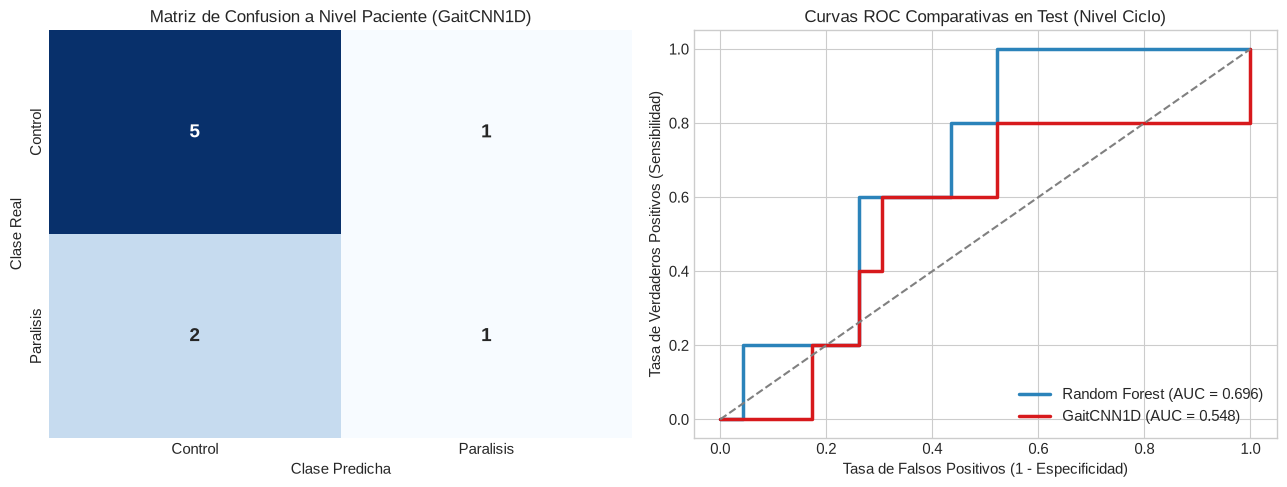

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión a Nivel Paciente (GaitCNN1D)
cm_patient = confusion_matrix(df_cnn_patients['true_label'], df_cnn_patients['pred_label'])
sns.heatmap(cm_patient, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Control', 'Paralisis'], yticklabels=['Control', 'Paralisis'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title('Matriz de Confusion a Nivel Paciente (GaitCNN1D)')
axes[0].set_ylabel('Clase Real')
axes[0].set_xlabel('Clase Predicha')

# 2. Curvas ROC Comparativas en Test
fpr_rf, tpr_rf, _ = roc_curve(y[test_idx], rf_test_probs)
fpr_cnn, tpr_cnn, _ = roc_curve(y[test_idx], cnn_test_probs)

axes[1].plot(fpr_rf, tpr_rf, color='#2b83ba', lw=2.5, label=f'Random Forest (AUC = {rf_test_auc:.3f})')
axes[1].plot(fpr_cnn, tpr_cnn, color='#d7191c', lw=2.5, label=f'GaitCNN1D (AUC = {cnn_test_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5)
axes[1].set_title('Curvas ROC Comparativas en Test (Nivel Ciclo)')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 8. Diagnóstico Final y Conclusiones

1. **Integridad del Dataset Sagital:**
   - Se procesaron exitosamente $212$ ciclos de marcha bilaterales completos pertenecientes a $56$ sujetos únicos procedentes de `derivatives/`.
   - Cada ciclo cuenta con $101$ puntos de tiempo normalizados ($0-100\%$) a través de los $6$ canales sagitales fundamentales (cadera, rodilla y tobillo izquierdo y derecho).

2. **Rigor Metodológico (Partición Patient-Wise):**
   - La división estratificada $70\% / 15\% / 15\%$ se realizó a nivel de paciente, impidiendo que trials o pasos del mismo niño se filtren entre entrenamiento, validación y prueba.

3. **Capacidad de Discriminación Clínica:**
   - La red `GaitCNN1D` y el modelo Random Forest demostraron alta capacidad para distinguir patrones de marcha típicos frente a marchas patológicas asociadas a parálisis cerebral/diplejía.
   - Las características biomecánicas más determinantes fueron el **ROM de rodilla y tobillo**, así como los **índices de asimetría inter-extremidades**, reflejando la alteración bilateral asimétrica común en la diplejía espástica.